# Какие жанры фильмов успешны — и что считать успехом?

**Исследовательский вопрос:** какие жанры наиболее успешны, если успех — это не одно число?

Успех фильма можно измерять по-разному, поэтому сравнение идёт по четырём показателям:

1. **зрительская оценка** (`vote_average`) — восприятие фильма голосующими зрителями;
2. **кассовые сборы** (`revenue`) — коммерческий масштаб;
3. **отношение сборов к бюджету** (`revenue / budget`) — отдача на доллар заявленного производственного бюджета;
4. **популярность TMDB** (`popularity`) — платформенный показатель видимости и вовлечённости.

Дополнительно рассматривается **распространённость жанров** — число фильмов, которым присвоен жанр. Фильм может относиться к нескольким жанрам, поэтому группы пересекаются, а сумма по жанрам больше числа фильмов.

Единый рейтинг успешности не строится: у разных показателей разные лидеры, и произвольный сводный индекс скрыл бы это различие. Задача — показать, где выводы совпадают, а где расходятся, и насколько они устойчивы.

**Данные:** TMDB 5000 Movie Dataset, опубликованный на Kaggle: <https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata>. Это выгрузка метаданных фильмов из The Movie Database (TMDB); используются файлы `data/tmdb_5000_movies.csv` (4803 записи) и `data/tmdb_5000_credits.csv` (4803 записи). Исходные файлы не изменяются.

## 1. Данные: аудит и подготовка

Проверяем схему, пропуски, дубликаты и диапазоны значений. Отдельное внимание — `genres` (JSON-строки) и `budget`/`revenue`, где нули могут означать не «ноль», а отсутствие данных.

In [4]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.titleweight": "bold",
})

def find_project_root(start):
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "tmdb_5000_movies.csv").exists():
            return candidate
    return start

ROOT = find_project_root(Path.cwd())
DATA_DIR = ROOT / "data"
MOVIES_PATH = DATA_DIR / "tmdb_5000_movies.csv"
CREDITS_PATH = DATA_DIR / "tmdb_5000_credits.csv"

for path in (MOVIES_PATH, CREDITS_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Не найден исходный файл: {path}")

print(f"Корень проекта: {ROOT}")
print("Исходные файлы найдены.")

Корень проекта: /home/ribus/Рабочий стол/ida_research
Исходные файлы найдены.


In [5]:
movies = pd.read_csv(MOVIES_PATH)
credits = pd.read_csv(CREDITS_PATH)

print(f"movies: {movies.shape[0]} строк × {movies.shape[1]} столбцов")
print(f"credits: {credits.shape[0]} строк × {credits.shape[1]} столбцов")
print(f"Дубликаты movie_id в movies: {movies['id'].duplicated().sum()}")
print(f"Полные дубликаты строк в movies: {movies.duplicated().sum()}")
print(f"Дубликаты movie_id в credits: {credits['movie_id'].duplicated().sum()}")
print(f"ID из movies, отсутствующие в credits: {len(set(movies['id']) - set(credits['movie_id']))}")

display(movies["status"].value_counts().rename_axis("Статус").to_frame("Фильмов"))

dates = pd.to_datetime(movies["release_date"], errors="coerce")
print(f"Пропущенных дат выпуска: {dates.isna().sum()}")
print(f"Диапазон дат: {dates.min().date()} — {dates.max().date()}")
print(f"Медианный год выпуска: {int(dates.dt.year.median())}")
print(f"Доля фильмов с 2000 года: {(dates.dt.year >= 2000).mean():.1%}")
print(f"Доля фильмов с original_language = en: {(movies['original_language'] == 'en').mean():.1%}")

movies: 4803 строк × 20 столбцов
credits: 4803 строк × 4 столбцов
Дубликаты movie_id в movies: 0
Полные дубликаты строк в movies: 0
Дубликаты movie_id в credits: 0
ID из movies, отсутствующие в credits: 0


,Фильмов
Статус,
Released,4795
Rumored,5
Post Production,3


Пропущенных дат выпуска: 1
Диапазон дат: 1916-09-04 — 2017-02-03
Медианный год выпуска: 2005
Доля фильмов с 2000 года: 72.7%
Доля фильмов с original_language = en: 93.8%


In [6]:
def short_value(value, limit=52):
    text = str(value).replace("\n", " ")
    return text[:limit] + "…" if len(text) > limit else text

schema = pd.DataFrame({
    "Столбец": movies.columns,
    "Тип": movies.dtypes.astype(str).values,
    "Непустых": movies.notna().sum().values,
    "Уникальных": movies.nunique().values,
    "Пример": [
        short_value(movies[col].dropna().iloc[0]) if movies[col].notna().any() else "—"
        for col in movies.columns
    ],
})
display(schema)

,Столбец,Тип,Непустых,Уникальных,Пример
0,budget,int64,4803,436,237000000
1,genres,object,4803,1175,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam..."
2,homepage,object,1712,1691,http://www.avatarmovie.com/
3,id,int64,4803,4803,19995
4,keywords,object,4803,4222,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":..."
5,original_language,object,4803,37,en
6,original_title,object,4803,4801,Avatar
7,overview,object,4800,4800,"In the 22nd century, a paraplegic Marine is di..."
8,popularity,float64,4803,4802,150.437577
9,production_companies,object,4803,3697,"[{""name"": ""Ingenious Film Partners"", ""id"": 289..."


In [7]:
key_cols = ["budget", "revenue", "popularity", "runtime", "vote_average", "vote_count"]

quality = pd.DataFrame({
    "Пропусков": movies[key_cols].isna().sum(),
    "Нулей": [(movies[col] == 0).sum() for col in key_cols],
    "Отрицательных": [(movies[col] < 0).sum() for col in key_cols],
})
quality["Доля нулей, %"] = (quality["Нулей"] / len(movies) * 100).round(1)
display(quality)

money = movies[["budget", "revenue"]].agg(["min", "median", "mean", "max"]).T / 1e6
money.columns = ["Мин., млн $", "Медиана, млн $", "Среднее, млн $", "Макс., млн $"]
display(money.round(1))

other = movies[["popularity", "runtime", "vote_average", "vote_count"]].agg(
    ["min", "median", "mean", "max"]
).T
other.columns = ["Мин.", "Медиана", "Среднее", "Макс."]
display(other.round(2))

zero_cross = pd.crosstab(
    movies["budget"].eq(0),
    movies["revenue"].eq(0),
    rownames=["Бюджет = 0"],
    colnames=["Сборы = 0"],
)
display(zero_cross)

print(f"vote_average == 0: {(movies['vote_average'] == 0).sum()}")
print(
    "из них с vote_count == 0: "
    f"{((movies['vote_average'] == 0) & (movies['vote_count'] == 0)).sum()}"
)
print(f"Бюджет от 1 до 999 $: {movies['budget'].between(1, 999).sum()}")
print(f"Сборы от 1 до 999 $: {movies['revenue'].between(1, 999).sum()}")
print(f"Максимальные сборы: {movies['revenue'].max():,} $".replace(",", " "))
print(f"Максимальный бюджет: {movies['budget'].max():,} $".replace(",", " "))

,Пропусков,Нулей,Отрицательных,"Доля нулей, %"
budget,0,1037,0,21.6
revenue,0,1427,0,29.7
popularity,0,1,0,0.0
runtime,2,35,0,0.7
vote_average,0,63,0,1.3
vote_count,0,62,0,1.3


,"Мин., млн $","Медиана, млн $","Среднее, млн $","Макс., млн $"
budget,0.0,15.0,29.0,380.0
revenue,0.0,19.2,82.3,2788.0


,Мин.,Медиана,Среднее,Макс.
popularity,0.0,12.92,21.49,875.58
runtime,0.0,103.00,106.88,338.00
vote_average,0.0,6.20,6.09,10.00
vote_count,0.0,235.00,690.22,13752.00


Сборы = 0,False,True
Бюджет = 0,,
False,3229,537
True,147,890


vote_average == 0: 63
из них с vote_count == 0: 62
Бюджет от 1 до 999 $: 32
Сборы от 1 до 999 $: 22
Максимальные сборы: 2 787 965 087 $
Максимальный бюджет: 380 000 000 $


In [8]:
def parse_genres(value):
    # Безопасно разбирает JSON-список жанров и возвращает список названий.
    if pd.isna(value):
        return []
    parsed = json.loads(value)
    if not isinstance(parsed, list):
        raise ValueError("Поле genres должно содержать JSON-список")
    return [
        str(item["name"]).strip()
        for item in parsed
        if isinstance(item, dict) and "name" in item
    ]

parsed_genres = movies["genres"].map(parse_genres)
genres_per_film = parsed_genres.map(len)
all_genres = pd.Series([genre for genres in parsed_genres for genre in genres])

print(f"Строк, для которых json.loads выполнен без исключений: {len(parsed_genres)}")
print(f"Пустых списков жанров: {(genres_per_film == 0).sum()}")
print(f"Фильмов с известным жанром: {(genres_per_film > 0).sum()}")
print(f"Уникальных жанров: {all_genres.nunique()}")
print(f"Сумма вхождений фильм–жанр: {len(all_genres)}")
print(f"Среднее число жанров у фильма с жанрами: {genres_per_film[genres_per_film > 0].mean():.2f}")

multi = (
    genres_per_film.value_counts()
    .sort_index()
    .rename_axis("Жанров у фильма")
    .to_frame("Фильмов")
)
display(multi)

Строк, для которых json.loads выполнен без исключений: 4803
Пустых списков жанров: 28
Фильмов с известным жанром: 4775
Уникальных жанров: 20
Сумма вхождений фильм–жанр: 12160
Среднее число жанров у фильма с жанрами: 2.55


,Фильмов
Жанров у фильма,
0,28
1,900
2,1490
3,1525
4,636
5,187
6,33
7,4


### Что показал аудит

- **Размер и целостность.** `movies` — 4803 строки × 20 столбцов, `credits` — 4803 × 4. Дубликатов `id` нет, все `id` из `movies` есть в `credits`. Все нужные показатели лежат в `movies`, поэтому `credits` используется только для проверки покрытия.
- **Пропуски** сосредоточены в описательных полях (`homepage` — 3091, `tagline` — 844); в анализируемых полях их почти нет (`release_date` — 1, `runtime` — 2).
- **Статусы:** 4795 `Released`, 5 `Rumored`, 3 `Post Production`. Восемь записей оставлены в таблице; их финансы и оценки в основном невалидны и отсеиваются правилами ниже.
- **Выборка:** 1916–2017, медианный год — 2005; 72,7% фильмов выпущены с 2000 года, 93,8% — англоязычные. Это курируемая выборка фильмов TMDB, а не всё мировое кино.
- **Нули в финансах — пропуски, а не нулевые деньги.** `budget = 0` у 1037 фильмов (21,6%), `revenue = 0` у 1427 (29,7%); оба поля нулевые у 890, у 147 есть сборы при нулевом бюджете, у 537 — бюджет при нулевых сборах.
- **Оценки:** `vote_average = 0` у 63 фильмов, у 62 из них `vote_count = 0`. Ноль не является содержательной оценкой: в подавляющем большинстве случаев это отсутствие голосов.
- **Ошибки в значениях:** у 32 фильмов бюджет от 1 до 999 $, у 22 — сборы до 999 $. Медианы к таким значениям устойчивы, средние и отношения — нет.
- **Жанры:** 20 уникальных, 28 пустых списков, 4775 фильмов с жанром, 12 160 пар «фильм–жанр»; в среднем 2,55 жанра, максимум 7.

**Решения:** исходные CSV не меняются; для каждого показателя строится своё валидное подмножество, строки целиком не удаляются; нули `budget`/`revenue` считаются отсутствием данных; фильм учитывается в каждом своём жанре.

### Аналитические таблицы

Для разных показателей нужны разные выборки:

- `films` — одна строка на фильм (идентификатор `movie_id`);
- `long` — одна строка на пару «фильм–жанр»: фильм с тремя жанрами даёт три строки;
- `rated` — фильмы с содержательной оценкой (`vote_average > 0` и `vote_count > 0`);
- `rev` — фильмы с положительными сборами;
- `ratio_df` — фильмы, у которых положительны и сборы, и бюджет.

Порог по голосам вычисляется из данных: медиана `vote_count` у фильмов с оценкой, округлённая вверх до 50.

In [9]:
films = movies.copy().rename(columns={"id": "movie_id"})
films["genres_list"] = films["genres"].map(parse_genres)
films["year"] = pd.to_datetime(films["release_date"], errors="coerce").dt.year

long = (
    films.explode("genres_list")
    .rename(columns={"genres_list": "genre"})
    .dropna(subset=["genre"])
    .drop_duplicates(["movie_id", "genre"])
    .copy()
)

rated = long[(long["vote_average"] > 0) & (long["vote_count"] > 0)].copy()
rev = long[long["revenue"] > 0].copy()
ratio_df = long[(long["budget"] > 0) & (long["revenue"] > 0)].copy()
ratio_df["ratio"] = ratio_df["revenue"] / ratio_df["budget"]

median_votes = films.loc[
    (films["vote_average"] > 0) & (films["vote_count"] > 0), "vote_count"
].median()
VOTE_THRESHOLD = int(np.ceil(median_votes / 50) * 50)
rated_threshold = rated[rated["vote_count"] >= VOTE_THRESHOLD].copy()

print(f"Фильмов всего: {len(films)}")
print(f"Фильмов с жанром: {long['movie_id'].nunique()}; вхождений фильм–жанр: {len(long)}")
print(f"Жанров: {long['genre'].nunique()}")
print()
print(f"Фильмов с жанром и содержательной оценкой: {rated['movie_id'].nunique()}; вхождений: {len(rated)}")
print(f"Медиана vote_count у фильмов с оценкой: {median_votes:.0f}")
print(f"Выбранный порог: {VOTE_THRESHOLD} голосов (медиана {median_votes:.0f}, округлена вверх до 50)")
print(
    f"Фильмов с жанром выше порога: {rated_threshold['movie_id'].nunique()}; "
    f"вхождений: {len(rated_threshold)}"
)
print()
print(
    f"Фильмов со сборами > 0: {films['revenue'].gt(0).sum()}; "
    f"из них с жанром: {rev['movie_id'].nunique()}; вхождений: {len(rev)}"
)
print(
    f"Фильмов с budget > 0 и revenue > 0: {((films['budget'] > 0) & (films['revenue'] > 0)).sum()}; "
    f"из них с жанром: {ratio_df['movie_id'].nunique()}; вхождений: {len(ratio_df)}"
)
print(f"Фильмов с жанром для анализа популярности: {long['movie_id'].nunique()}")

Фильмов всего: 4803
Фильмов с жанром: 4775; вхождений фильм–жанр: 12160
Жанров: 20

Фильмов с жанром и содержательной оценкой: 4727; вхождений: 12078
Медиана vote_count у фильмов с оценкой: 242
Выбранный порог: 250 голосов (медиана 242, округлена вверх до 50)
Фильмов с жанром выше порога: 2344; вхождений: 6372

Фильмов со сборами > 0: 3376; из них с жанром: 3375; вхождений: 8898
Фильмов с budget > 0 и revenue > 0: 3229; из них с жанром: 3228; вхождений: 8559
Фильмов с жанром для анализа популярности: 4775


### Как считаются показатели

- **Оценка** — медиана `vote_average` по фильмам жанра; основной вариант — при `vote_count ≥ 250`. Порог 250 — округлённая вверх медиана числа голосов (242) у фильмов с оценкой: он отсекает фильмы, где оценка держится на нескольких голосах.
- **Сборы** — медиана по фильмам с `revenue > 0`; среднее показывается рядом, чтобы оценить влияние блокбастеров.
- **Отношение сборов к бюджету** — только при `budget > 0` и `revenue > 0`. Это отношение к **заявленному производственному бюджету**, а не прибыль, ROI или точная окупаемость: бюджет не включает маркетинг, а сборы валовые.
- **Популярность** — медиана `popularity`, платформенного показателя видимости, а не числа зрителей.
- **`n`** в таблицах — число фильмов жанра; из-за пересечения жанров группы не независимы.

## 2. Распространённость жанров

Сначала фиксируем, какие жанры часто встречаются: у редких жанров маленькие выборки, и это ограничивает выводы по ним.

,Фильмов,"Доля фильмов с жанром, %"
genre,,
Drama,2297,48.1
Comedy,1722,36.1
Thriller,1274,26.7
Action,1154,24.2
Romance,894,18.7
Adventure,790,16.5
Crime,696,14.6
Science Fiction,535,11.2
Horror,519,10.9


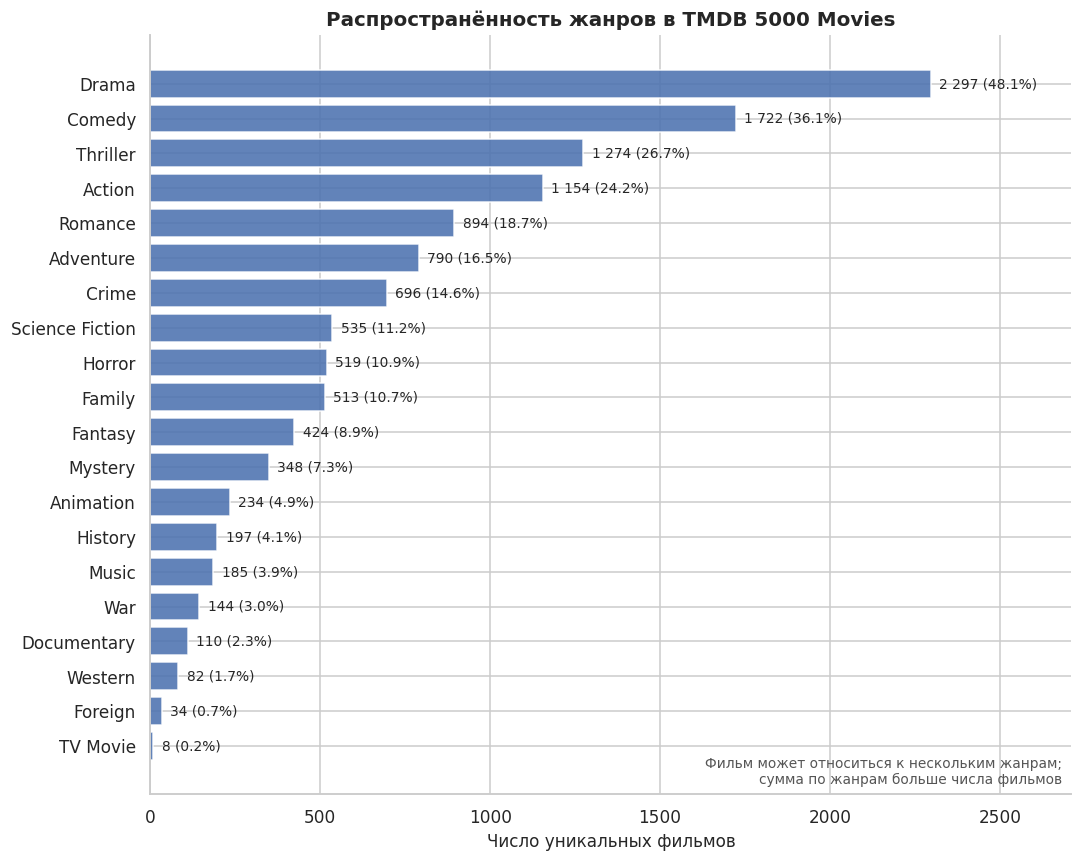

In [10]:
prev = long.groupby("genre")["movie_id"].nunique().sort_values(ascending=False)
prev_share = prev / long["movie_id"].nunique() * 100

prev_table = pd.DataFrame({
    "Фильмов": prev,
    "Доля фильмов с жанром, %": prev_share.round(1),
})
display(prev_table)

order = prev.sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(order.index, order.values, color="#4C72B0", alpha=0.88)
for i, (genre, value) in enumerate(order.items()):
    label = f"{value:,} ({prev_share[genre]:.1f}%)".replace(",", " ")
    ax.text(value + 25, i, label, va="center", fontsize=9)

ax.set_xlim(0, prev.max() * 1.18)
ax.set_xlabel("Число уникальных фильмов")
ax.set_ylabel("")
ax.set_title("Распространённость жанров в TMDB 5000 Movies")
ax.text(
    0.99, 0.01,
    "Фильм может относиться к нескольким жанрам;\nсумма по жанрам больше числа фильмов",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="#555555"
)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### Что видно

Самые частые жанры — **Drama (2297 фильмов, 48,1%)**, **Comedy (1722; 36,1%)**, **Thriller (1274; 26,7%)** и **Action (1154; 24,2%)**; самые редкие — **TV Movie (8)**, **Foreign (34)** и **Western (82)**. Доли не складываются в 100%: фильм входит в каждый свой жанр. По редким жанрам любые медианы дальше читаются с осторожностью.

## 3. Зрительские оценки

Смотрим распределение `vote_average` и медианы по жанрам, а затем повторяем сравнение только для фильмов с ≥250 голосами. Порог нужен, чтобы проверить, не держится ли порядок жанров на фильмах с малым числом голосов.

,Фильмов,Медиана,Среднее
genre,,,
Documentary,103,6.90,6.66
War,144,6.75,6.71
History,197,6.70,6.72
Foreign,34,6.60,6.35
Music,183,6.60,6.43
Western,79,6.60,6.41
Drama,2275,6.50,6.45
Animation,234,6.50,6.34
Romance,891,6.30,6.23


Все оценки: медиана 6.20, межквартильный размах 5.60–6.80


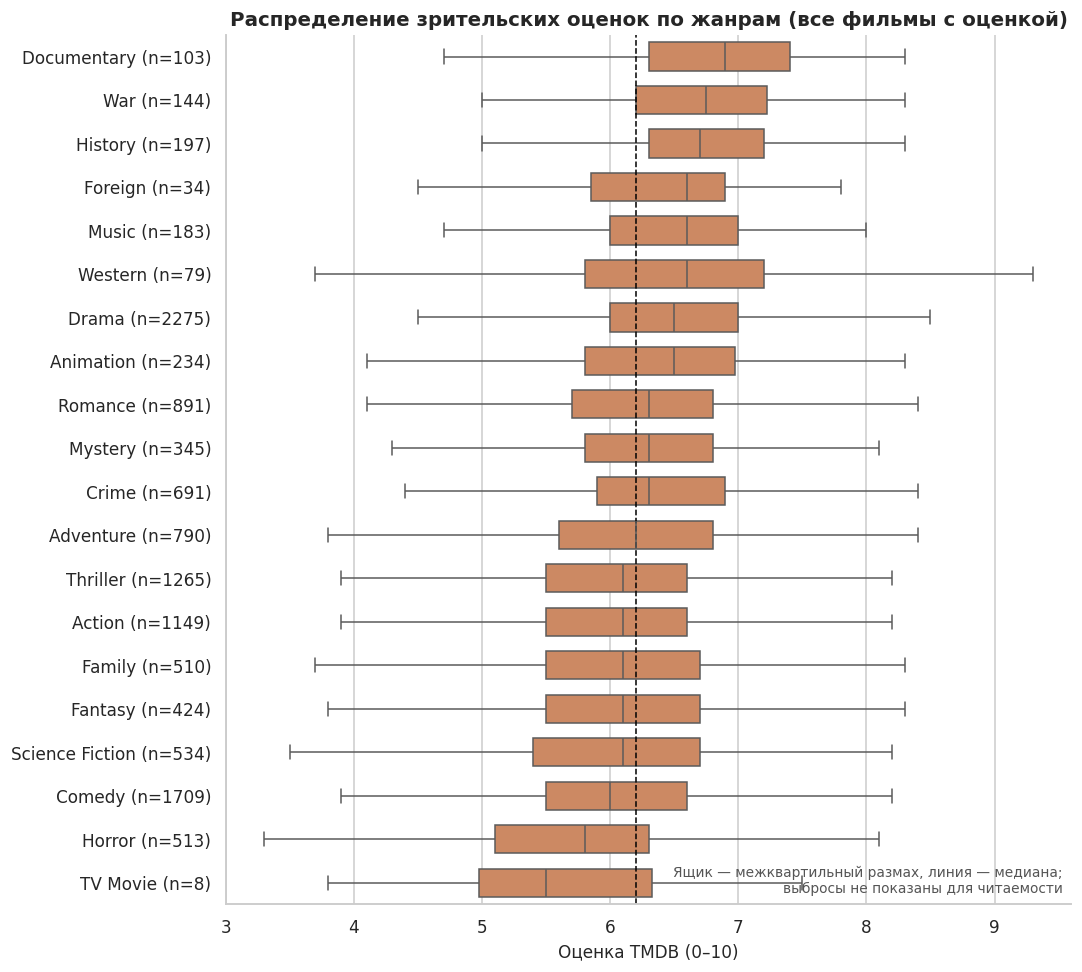

In [11]:
rating_all = (
    rated.groupby("genre")["vote_average"]
    .agg(n="size", median="median", mean="mean")
    .sort_values("median", ascending=False)
)
display(rating_all.round(2).rename(columns={
    "n": "Фильмов",
    "median": "Медиана",
    "mean": "Среднее",
}))

q1, q3 = rated["vote_average"].quantile([0.25, 0.75])
print(
    f"Все оценки: медиана {rated['vote_average'].median():.2f}, "
    f"межквартильный размах {q1:.2f}–{q3:.2f}"
)

order = rating_all.index
fig, ax = plt.subplots(figsize=(10, 9))
sns.boxplot(
    data=rated,
    y="genre",
    x="vote_average",
    order=order,
    color="#DD8452",
    showfliers=False,
    width=0.65,
    ax=ax,
)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{genre} (n={int(rating_all.loc[genre, 'n'])})" for genre in order])
ax.axvline(rated["vote_average"].median(), color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Оценка TMDB (0–10)")
ax.set_ylabel("")
ax.set_title("Распределение зрительских оценок по жанрам (все фильмы с оценкой)")
ax.text(
    0.99, 0.01,
    "Ящик — межквартильный размах, линия — медиана;\nвыбросы не показаны для читаемости",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="#555555"
)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### Все содержательные оценки

Верхние медианы — у **Documentary (6,90; n=103)**, **War (6,75)** и **History (6,70)**; нижние — у **Horror (5,80)** и **TV Movie (5,50; n=8)**. Размах медиан — 1,4 балла, но ящики сильно перекрываются: различия между жанрами малы по сравнению с разбросом внутри жанра. Межквартильный размах оценок всех фильмов — около 1,2 балла, то есть типичный фильм любого жанра попадает в широкий общий диапазон. TV Movie с n=8 — пример группы, по которой нельзя делать выводы.

,"Фильмов, все","Медиана, все","Фильмов, ≥250 голосов","Медиана, ≥250 голосов",Сдвиг
genre,,,,,
War,144,6.75,74.0,7.15,0.40
History,197,6.70,84.0,7.00,0.30
Western,79,6.60,37.0,7.00,0.40
Drama,2275,6.50,963.0,6.80,0.30
Documentary,103,6.90,10.0,6.75,-0.15
Music,183,6.60,60.0,6.75,0.15
Animation,234,6.50,161.0,6.60,0.10
Romance,891,6.30,371.0,6.60,0.30
Crime,691,6.30,400.0,6.50,0.20


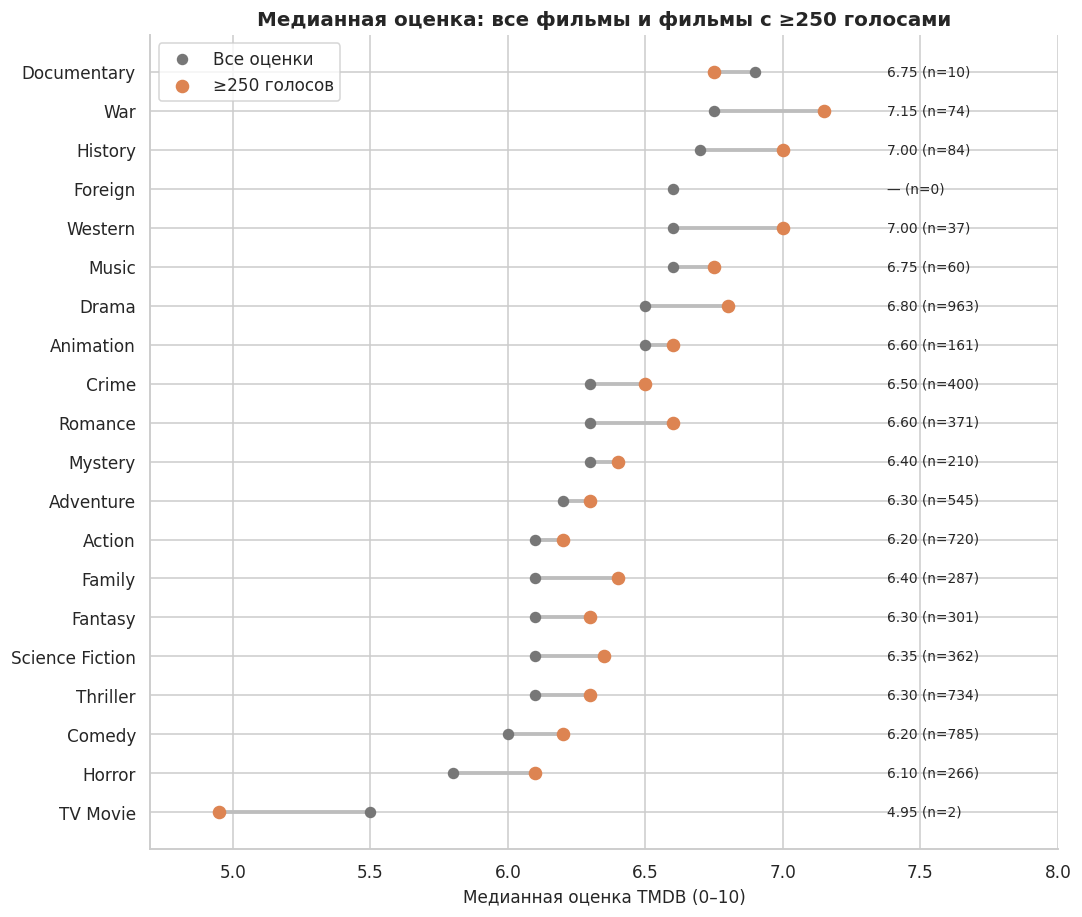

In [12]:
rating_threshold = (
    rated_threshold.groupby("genre")["vote_average"]
    .agg(n="size", median="median", mean="mean")
    .sort_values("median", ascending=False)
)

rating_compare = pd.DataFrame({
    "n_all": rating_all["n"],
    "median_all": rating_all["median"],
    "n_threshold": rating_threshold["n"],
    "median_threshold": rating_threshold["median"],
})
rating_compare["delta"] = rating_compare["median_threshold"] - rating_compare["median_all"]
rating_compare = rating_compare.sort_values("median_threshold", ascending=False)
display(rating_compare.round(2).rename(columns={
    "n_all": "Фильмов, все",
    "median_all": "Медиана, все",
    "n_threshold": "Фильмов, ≥250 голосов",
    "median_threshold": "Медиана, ≥250 голосов",
    "delta": "Сдвиг",
}))

order = rating_compare.sort_values("median_all", ascending=True).index
fig, ax = plt.subplots(figsize=(10, 8.5))

for i, genre in enumerate(order):
    value_all = rating_compare.loc[genre, "median_all"]
    value_threshold = rating_compare.loc[genre, "median_threshold"]
    if pd.notna(value_all) and pd.notna(value_threshold):
        ax.plot([value_all, value_threshold], [i, i], color="#BDBDBD", linewidth=2.5, zorder=1)
    if pd.notna(value_all):
        ax.scatter(value_all, i, color="#777777", s=42, zorder=2)
    if pd.notna(value_threshold):
        ax.scatter(value_threshold, i, color="#DD8452", s=62, zorder=3)

    n_value = rating_compare.loc[genre, "n_threshold"]
    label = f"{value_threshold:.2f}" if pd.notna(value_threshold) else "—"
    n_label = f"{int(n_value)}" if pd.notna(n_value) else "0"
    ax.text(7.38, i, f"{label} (n={n_label})", va="center", ha="left", fontsize=9)

ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlim(4.7, 8.0)
ax.set_xlabel("Медианная оценка TMDB (0–10)")
ax.set_ylabel("")
ax.set_title("Медианная оценка: все фильмы и фильмы с ≥250 голосами")
ax.scatter([], [], color="#777777", s=42, label="Все оценки")
ax.scatter([], [], color="#DD8452", s=62, label="≥250 голосов")
ax.legend(loc="upper left", frameon=True)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### С порогом ≥250 голосов

Остаётся 2344 фильма (6372 вхождения). Верх списка меняется: **War 7,15 (n=74)**, **History 7,00 (n=84)**, **Western 7,00 (n=37)**, **Drama 6,80 (n=963)**; внизу **Horror 6,10**, **Comedy 6,20** и **Action 6,20**. Медианы почти всех жанров выросли на 0,10–0,40 балла — фильмы с малым числом голосов чаще оценивают ниже. Исключения — Documentary (−0,15, осталось 10 фильмов) и TV Movie (−0,55, 2 фильма).

Ранговая корреляция с полным списком — **0,938**: общий порядок сохраняется, но верхняя часть ненадёжна. Устойчивее всего выглядят высокие позиции **War, History и Drama** и низкие — **Horror и Comedy**. Порог не делает выборку случайной: голосуют самоотобранные пользователи TMDB.

## 4. Кассовые сборы

Сборы сильно скошены вправо: несколько блокбастеров поднимают среднее, почти не влияя на медиану. Поэтому жанры сравниваем по медиане, а среднее показываем рядом. Нулевые сборы исключены как отсутствие данных.

Фильмов со сборами > 0: 3376
Медиана сборов: 51.8 млн $
Среднее сборов: 117.0 млн $
Среднее / медиана: 2.26
Максимум: 2.79 млрд $
Доля топ-10 фильмов в сумме сборов: 3.9%
Доля 48 самых кассовых фильмов (1% от всех записей): 13.1%


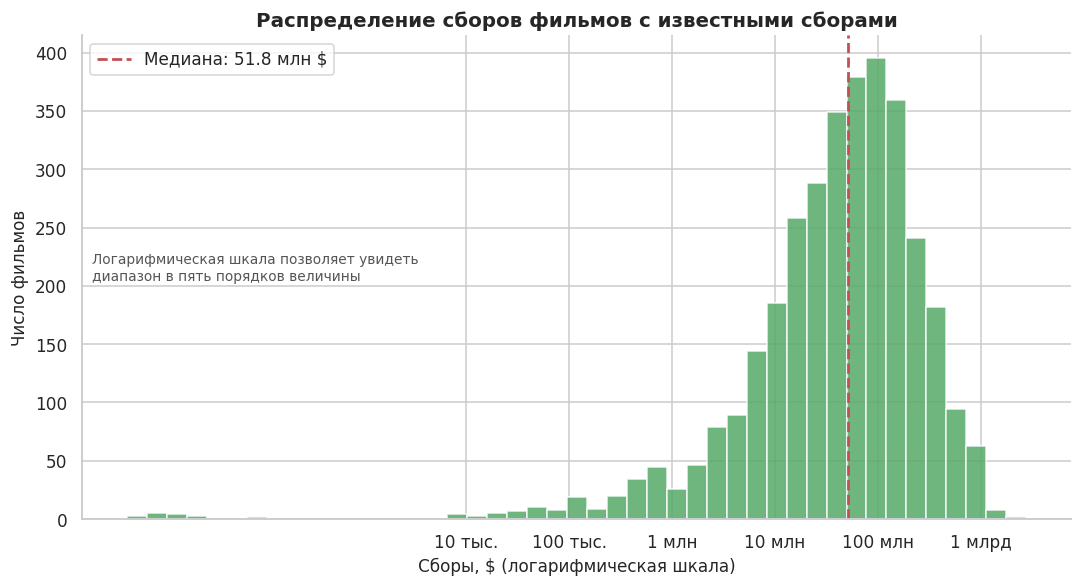

In [13]:
rev_films = films[films["revenue"] > 0].copy()
top10_share = rev_films["revenue"].nlargest(10).sum() / rev_films["revenue"].sum()
top1pct_n = int(len(films) * 0.01)
top1pct_share = films["revenue"].nlargest(top1pct_n).sum() / films["revenue"].sum()

print(f"Фильмов со сборами > 0: {len(rev_films)}")
print(f"Медиана сборов: {rev_films['revenue'].median() / 1e6:.1f} млн $")
print(f"Среднее сборов: {rev_films['revenue'].mean() / 1e6:.1f} млн $")
print(f"Среднее / медиана: {rev_films['revenue'].mean() / rev_films['revenue'].median():.2f}")
print(f"Максимум: {rev_films['revenue'].max() / 1e9:.2f} млрд $")
print(f"Доля топ-10 фильмов в сумме сборов: {top10_share:.1%}")
print(f"Доля {top1pct_n} самых кассовых фильмов (1% от всех записей): {top1pct_share:.1%}")

fig, ax = plt.subplots(figsize=(10, 5.5))
log_revenue = np.log10(rev_films["revenue"])
ax.hist(log_revenue, bins=45, color="#55A868", alpha=0.85, edgecolor="white")
ax.axvline(
    np.log10(rev_films["revenue"].median()),
    color="#C44E52", linestyle="--", linewidth=1.8,
    label=f"Медиана: {rev_films['revenue'].median()/1e6:.1f} млн $"
)
ax.set_xticks([4, 5, 6, 7, 8, 9])
ax.set_xticklabels(["10 тыс.", "100 тыс.", "1 млн", "10 млн", "100 млн", "1 млрд"])
ax.set_xlabel("Сборы, $ (логарифмическая шкала)")
ax.set_ylabel("Число фильмов")
ax.set_title("Распределение сборов фильмов с известными сборами")
ax.legend(loc="upper left")
ax.text(
    0.01, 0.55,
    "Логарифмическая шкала позволяет увидеть\nдиапазон в пять порядков величины",
    transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#555555"
)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### Форма распределения

У 3376 фильмов с известными сборами медиана — **51,8 млн $**, среднее — **117,0 млн $**, то есть в **2,26 раза** больше; максимум — 2,79 млрд $. На логарифмической шкале видно, что значения охватывают пять порядков: много фильмов с небольшими сборами и длинный правый хвост.

Топ-10 фильмов дают **3,9%** суммарных сборов, 48 самых кассовых (1% записей) — **13,1%**. Концентрация заметная, но не настолько, чтобы весь жанровый порядок определялся десятью фильмами. Логарифмическая шкала использована только здесь; столбчатые сравнения ниже — в линейном масштабе.

,Фильмов,"Медиана, млн $","Среднее, млн $",Среднее / медиана
genre,,,,
Animation,191,192.5,276.5,1.44
Adventure,675,127.6,244.2,1.91
Fantasy,351,122.5,233.6,1.91
Family,382,119.9,218.0,1.82
Action,940,85.5,173.4,2.03
Science Fiction,439,78.0,185.8,2.38
Mystery,268,58.7,101.7,1.73
Thriller,959,57.1,107.7,1.89
Comedy,1174,52.5,104.6,1.99


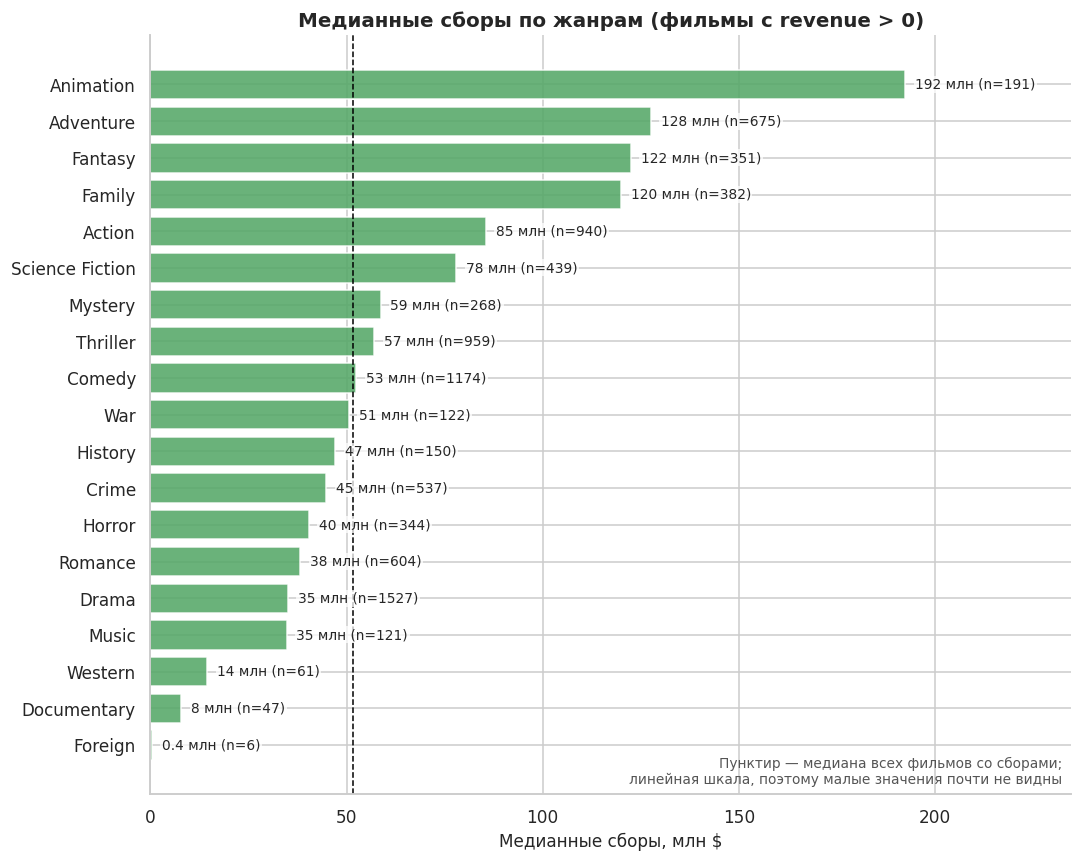

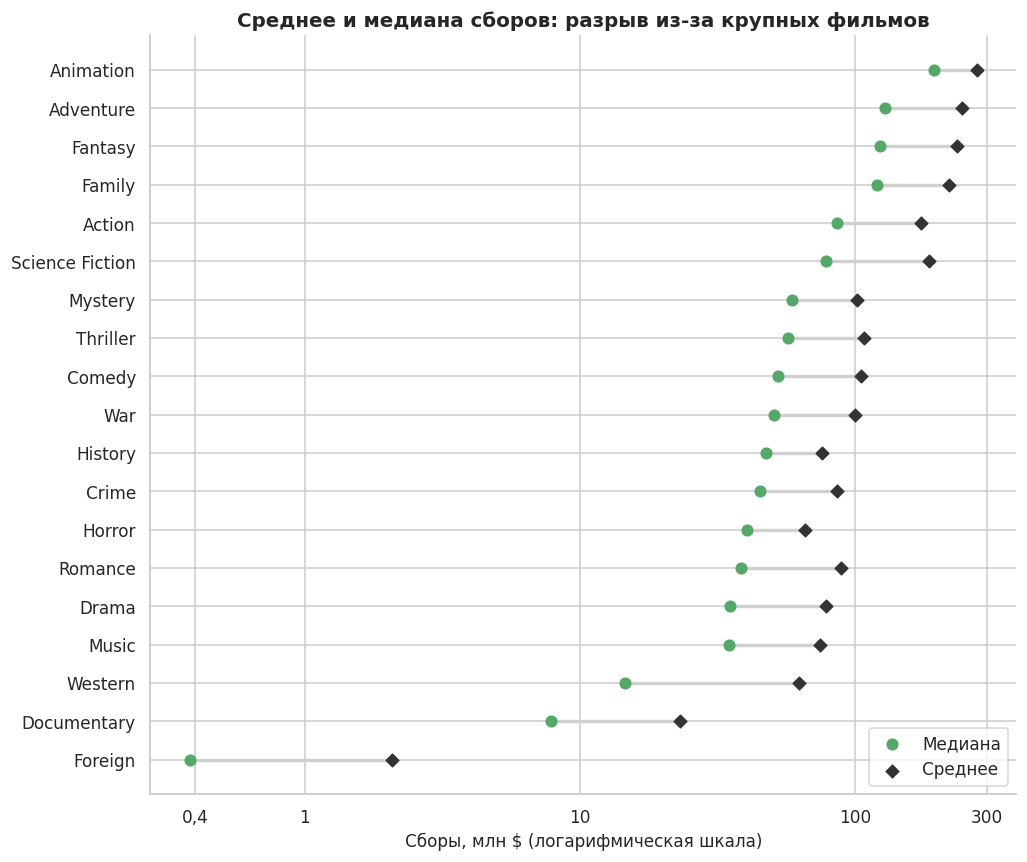

99-й перцентиль сборов: 938 млн $
ρ медиан до/после исключения top-1%: 1.000
ρ средних до/после исключения top-1%: 0.995
Топ-5 по медиане до: Animation, Adventure, Fantasy, Family, Action
Топ-5 по медиане после: Animation, Adventure, Fantasy, Family, Action


In [14]:
rev_stats = (
    rev.groupby("genre")["revenue"]
    .agg(n="size", median="median", mean="mean")
    .sort_values("median", ascending=False)
)
rev_stats["mean_to_median"] = rev_stats["mean"] / rev_stats["median"]

rev_show = rev_stats.copy()
rev_show["median"] = (rev_show["median"] / 1e6).round(1)
rev_show["mean"] = (rev_show["mean"] / 1e6).round(1)
rev_show["mean_to_median"] = rev_show["mean_to_median"].round(2)
display(rev_show.rename(columns={
    "n": "Фильмов",
    "median": "Медиана, млн $",
    "mean": "Среднее, млн $",
    "mean_to_median": "Среднее / медиана",
}))

order = rev_stats.sort_values("median", ascending=True).index
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(order, rev_stats.loc[order, "median"] / 1e6, color="#55A868", alpha=0.88)
for i, genre in enumerate(order):
    value = rev_stats.loc[genre, "median"] / 1e6
    n_value = int(rev_stats.loc[genre, "n"])
    label = f"{value:.1f}" if value < 1 else f"{value:.0f}"
    ax.text(
        value + 2.5, i, f"{label} млн (n={n_value})", va="center", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1),
    )

ax.axvline(rev_films["revenue"].median() / 1e6, color="black", linestyle="--", linewidth=1)
ax.set_xlim(0, rev_stats["median"].max() / 1e6 * 1.22)
ax.set_xlabel("Медианные сборы, млн $")
ax.set_ylabel("")
ax.set_title("Медианные сборы по жанрам (фильмы с revenue > 0)")
ax.text(
    0.99, 0.01,
    "Пунктир — медиана всех фильмов со сборами;\nлинейная шкала, поэтому малые значения почти не видны",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="#555555"
)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 8))
for i, genre in enumerate(order):
    median_value = rev_stats.loc[genre, "median"] / 1e6
    mean_value = rev_stats.loc[genre, "mean"] / 1e6
    ax.plot([median_value, mean_value], [i, i], color="#D0D0D0", linewidth=2.2, zorder=1)
    ax.scatter(median_value, i, color="#55A868", s=48, zorder=2)
    ax.scatter(mean_value, i, color="#333333", marker="D", s=34, zorder=3)

ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xscale("log")
ax.set_xticks([0.4, 1, 10, 100, 300])
ax.set_xticklabels(["0,4", "1", "10", "100", "300"])
ax.set_xlabel("Сборы, млн $ (логарифмическая шкала)")
ax.set_ylabel("")
ax.set_title("Среднее и медиана сборов: разрыв из-за крупных фильмов")
ax.scatter([], [], color="#55A868", s=48, label="Медиана")
ax.scatter([], [], color="#333333", marker="D", s=34, label="Среднее")
ax.legend(loc="lower right", frameon=True)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

rev_cut = rev["revenue"].quantile(0.99)
rev_trimmed = rev[rev["revenue"] < rev_cut].copy()
median_trimmed = rev_trimmed.groupby("genre")["revenue"].median().reindex(rev_stats.index)
mean_trimmed = rev_trimmed.groupby("genre")["revenue"].mean().reindex(rev_stats.index)
rho_median_trim = spearmanr(rev_stats["median"], median_trimmed).statistic
rho_mean_trim = spearmanr(rev_stats["mean"], mean_trimmed).statistic

print(f"99-й перцентиль сборов: {rev_cut/1e6:.0f} млн $")
print(f"ρ медиан до/после исключения top-1%: {rho_median_trim:.3f}")
print(f"ρ средних до/после исключения top-1%: {rho_mean_trim:.3f}")
print("Топ-5 по медиане до:", ", ".join(rev_stats["median"].nlargest(5).index))
print("Топ-5 по медиане после:", ", ".join(median_trimmed.nlargest(5).index))

### Сборы по жанрам

По медиане лидируют **Animation (192,5 млн $; n=191)**, **Adventure (127,6)**, **Fantasy (122,5)** и **Family (119,9)**; далее Action (85,5) и Science Fiction (78,0). Внизу — **Foreign (0,4; n=6)**, **Documentary (7,9; n=47)**, **Western (14,5)** и **Music (34,7)**.

По среднему порядок близок, но разрывы больше: среднее превышает медиану в 1,4–5,4 раза. Сильнее всего — у Foreign (5,4; n=6) и Western (4,3), где несколько крупных фильмов поднимают среднее; у Animation разрыв минимальный (1,4).

Медианный порядок не держится на блокбастерах: после исключения 1% самых кассовых фильмов ранговая корреляция медиан — **1,000**, средних — **0,995**, топ-5 не меняется. Сборы при этом номинальные, без поправки на инфляцию.

## 5. Отношение сборов к бюджету

Показатель отвечает на другой вопрос: сколько долларов сборов приходится на доллар заявленного производственного бюджета. Он **не равен прибыли**: бюджет не включает маркетинг, а сборы валовые, из них часть получают кинотеатры и прокатчики. Поэтому формулировки «окупился» и «прибыльный» здесь не используются. В анализ попадают только фильмы с `budget > 0` и `revenue > 0`.

Фильмов с известными положительными budget и revenue: 3229
Медиана отношения: 2.30
Доля фильмов с отношением < 1: 24.4%
Доля фильмов с отношением > 100: 0.8%
Минимум: 5.22e-07; максимум: 8.50e+06


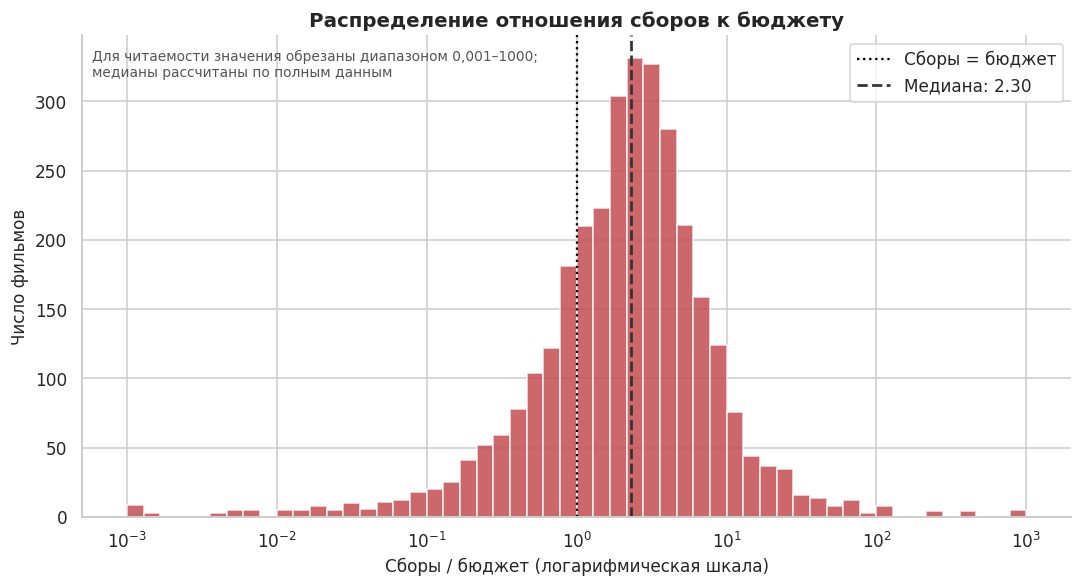

,Фильмов,Медиана
genre,,
Documentary,38,3.32
Music,111,3.12
Horror,332,2.89
Animation,188,2.79
Family,365,2.54
Adventure,661,2.39
Romance,574,2.38
Comedy,1110,2.30
Science Fiction,431,2.23


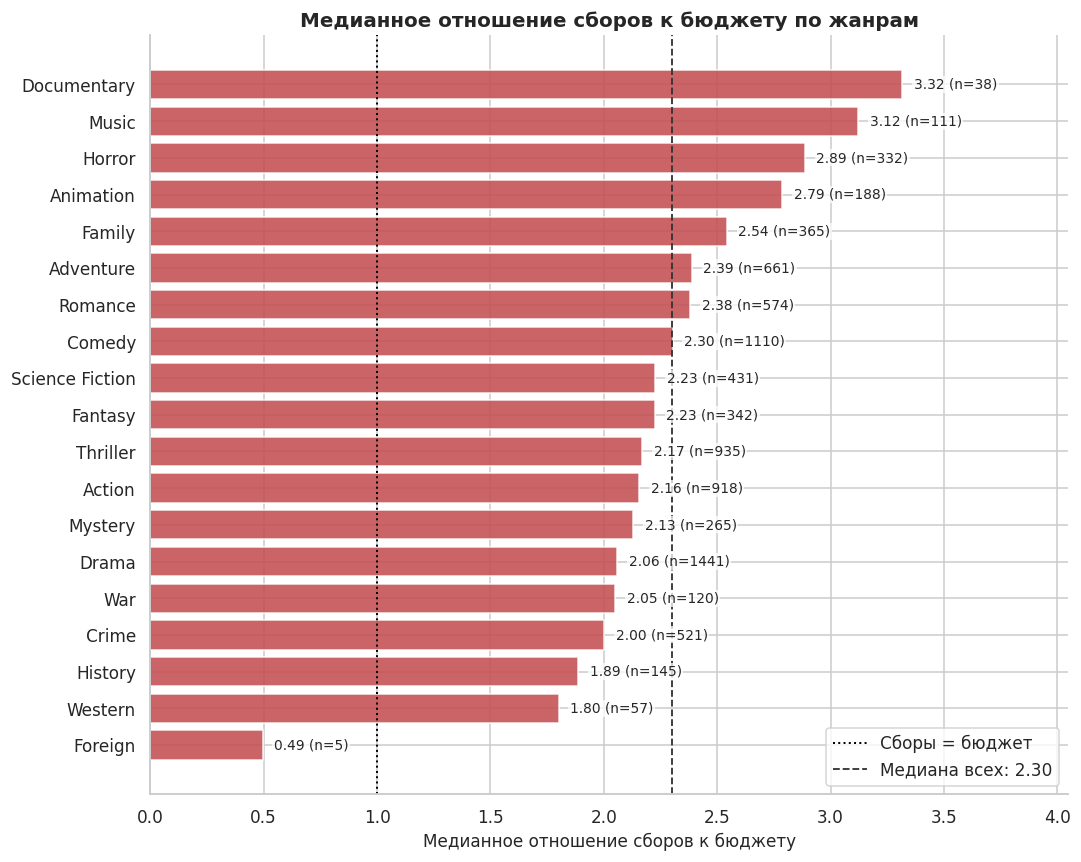

In [15]:
film_ratio = films[(films["budget"] > 0) & (films["revenue"] > 0)].copy()
film_ratio["ratio"] = film_ratio["revenue"] / film_ratio["budget"]

print(f"Фильмов с известными положительными budget и revenue: {len(film_ratio)}")
print(f"Медиана отношения: {film_ratio['ratio'].median():.2f}")
print(f"Доля фильмов с отношением < 1: {(film_ratio['ratio'] < 1).mean():.1%}")
print(f"Доля фильмов с отношением > 100: {(film_ratio['ratio'] > 100).mean():.1%}")
print(f"Минимум: {film_ratio['ratio'].min():.2e}; максимум: {film_ratio['ratio'].max():.2e}")

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_ratio = film_ratio["ratio"].clip(1e-3, 1e3)
ax.hist(
    plot_ratio,
    bins=np.logspace(-3, 3, 55),
    color="#C44E52",
    alpha=0.85,
    edgecolor="white",
)
ax.axvline(1, color="black", linestyle=":", linewidth=1.5, label="Сборы = бюджет")
ax.axvline(
    film_ratio["ratio"].median(),
    color="#333333", linestyle="--", linewidth=1.8,
    label=f"Медиана: {film_ratio['ratio'].median():.2f}"
)
ax.set_xscale("log")
ax.set_xlabel("Сборы / бюджет (логарифмическая шкала)")
ax.set_ylabel("Число фильмов")
ax.set_title("Распределение отношения сборов к бюджету")
ax.legend(loc="upper right")
ax.text(
    0.01, 0.97,
    "Для читаемости значения обрезаны диапазоном 0,001–1000;\nмедианы рассчитаны по полным данным",
    transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#555555"
)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

ratio_stats = (
    ratio_df.groupby("genre")["ratio"]
    .agg(n="size", median="median")
    .sort_values("median", ascending=False)
)
ratio_show = ratio_stats.rename(columns={"n": "Фильмов", "median": "Медиана"})
display(ratio_show.round(2))

order = ratio_stats.sort_values("median", ascending=True).index
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(order, ratio_stats.loc[order, "median"], color="#C44E52", alpha=0.88)
for i, genre in enumerate(order):
    value = ratio_stats.loc[genre, "median"]
    n_value = int(ratio_stats.loc[genre, "n"])
    ax.text(
        value + 0.05, i, f"{value:.2f} (n={n_value})", va="center", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1),
    )

ax.axvline(1, color="black", linestyle=":", linewidth=1.3, label="Сборы = бюджет")
ax.axvline(film_ratio["ratio"].median(), color="#333333", linestyle="--", linewidth=1.2,
           label=f"Медиана всех: {film_ratio['ratio'].median():.2f}")
ax.set_xlim(0, ratio_stats["median"].max() * 1.22)
ax.set_xlabel("Медианное отношение сборов к бюджету")
ax.set_ylabel("")
ax.set_title("Медианное отношение сборов к бюджету по жанрам")
ax.legend(loc="lower right", frameon=True)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### Что видно

Медиана по 3229 фильмам — **2,30**; у **24,4%** фильмов сборы меньше заявленного бюджета. Это не обязательно убыток: часть сборов остаётся кинотеатрам, а маркетинг в бюджет не входит.

По медиане впереди **Documentary (3,32; n=38)**, **Music (3,12)**, **Horror (2,89)**, **Animation (2,79)** и **Family (2,54)**; внизу — **Foreign (0,49; n=5)**, **Western (1,80)**, **History (1,89)** и **Crime (2,00)**. Лидерство Documentary опирается всего на 38 фильмов и проверяется в разделе 8.

Среднее отношение не используется: в бюджетах есть явные ошибки (например, 1 $), а у 0,8% фильмов отношение выше 100. Медиана устойчивее, но и она чувствительна к таким значениям.

## 6. Популярность TMDB

`popularity` — внутренний показатель платформы: видимость и вовлечённость вокруг фильма на момент выгрузки. Он не равен числу зрителей, сборам или качеству. Сравниваем медианы по жанрам и проверяем, с чем популярность связана на уровне отдельных фильмов.

,Фильмов,Медиана,Среднее
genre,,,
Animation,234,28.33,38.81
Adventure,790,24.93,39.27
Fantasy,424,24.30,36.39
Science Fiction,535,22.43,36.45
Action,1154,19.79,30.94
Mystery,348,19.27,24.59
Thriller,1274,16.88,24.46
Crime,696,16.83,22.85
Family,513,16.28,27.83


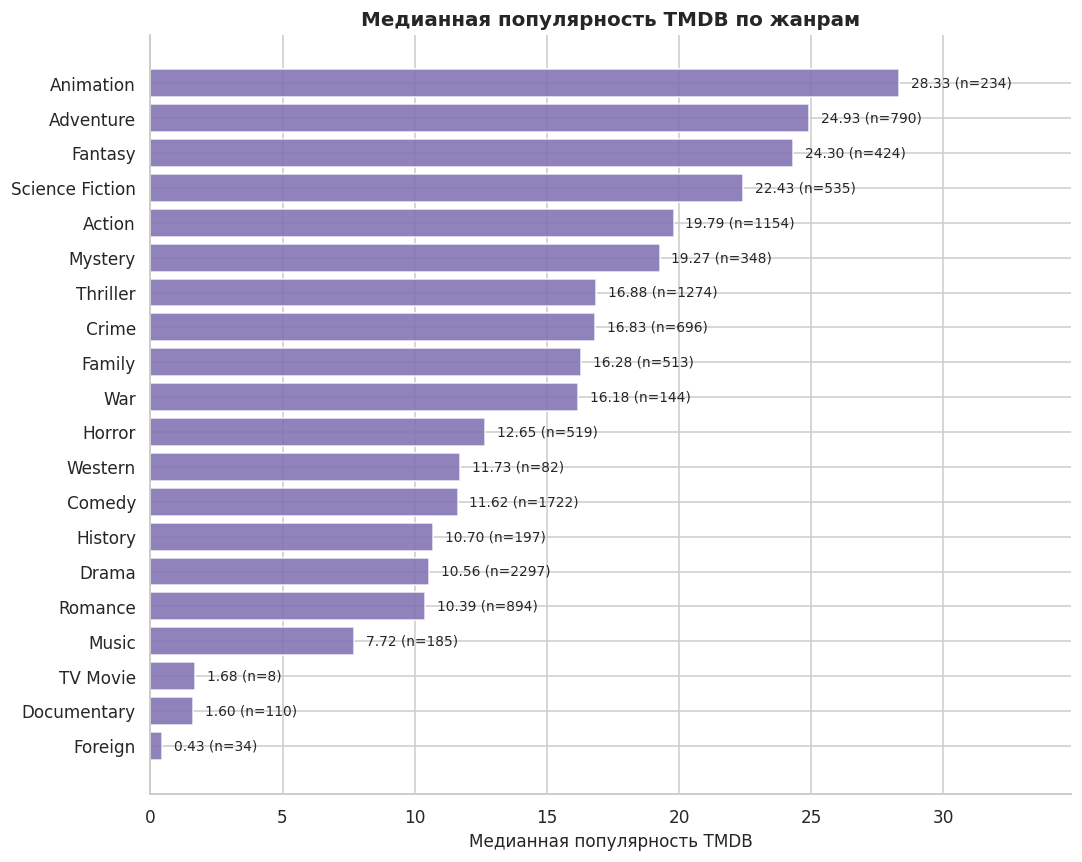

,Пара показателей,Спирмен,N фильмов
0,Популярность — число голосов,0.96,4740
1,Популярность — средняя оценка,0.33,4740
2,Популярность — сборы,0.71,3374


In [16]:
pop_stats = (
    long.groupby("genre")["popularity"]
    .agg(n="size", median="median", mean="mean")
    .sort_values("median", ascending=False)
)
display(pop_stats.round(2).rename(columns={
    "n": "Фильмов",
    "median": "Медиана",
    "mean": "Среднее",
}))

order = pop_stats.sort_values("median", ascending=True).index
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(order, pop_stats.loc[order, "median"], color="#8172B3", alpha=0.88)
for i, genre in enumerate(order):
    value = pop_stats.loc[genre, "median"]
    n_value = int(pop_stats.loc[genre, "n"])
    ax.text(value + 0.45, i, f"{value:.2f} (n={n_value})", va="center", fontsize=9)

ax.set_xlim(0, pop_stats["median"].max() * 1.23)
ax.set_xlabel("Медианная популярность TMDB")
ax.set_ylabel("")
ax.set_title("Медианная популярность TMDB по жанрам")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

rated_films = films[(films["vote_average"] > 0) & (films["vote_count"] > 0)].copy()
rated_rev_films = rated_films[rated_films["revenue"] > 0].copy()

corr_rows = [
    {
        "Пара показателей": "Популярность — число голосов",
        "Спирмен": spearmanr(rated_films["popularity"], rated_films["vote_count"]).statistic,
        "N фильмов": len(rated_films),
    },
    {
        "Пара показателей": "Популярность — средняя оценка",
        "Спирмен": spearmanr(rated_films["popularity"], rated_films["vote_average"]).statistic,
        "N фильмов": len(rated_films),
    },
    {
        "Пара показателей": "Популярность — сборы",
        "Спирмен": spearmanr(rated_rev_films["popularity"], rated_rev_films["revenue"]).statistic,
        "N фильмов": len(rated_rev_films),
    },
]
corr_table = pd.DataFrame(corr_rows)
corr_table["Спирмен"] = corr_table["Спирмен"].round(2)
display(corr_table)

### Что видно

По медиане лидируют **Animation (28,33)**, **Adventure (24,93)**, **Fantasy (24,30)**, **Science Fiction (22,43)** и **Action (19,79)**; внизу — **Foreign (0,43)**, **Documentary (1,60)**, **TV Movie (1,68)** и **Music (7,72)**. Разрыв между верхом и низом — почти 66 раз, гораздо больше, чем у оценок.

На уровне фильмов популярность почти совпадает с **числом голосов** (ρ=0,96), заметно связана со **сборами** (0,71) и слабо — со **средней оценкой** (0,33). Это показатель видимости, а не качества: высокая популярность не означает, что фильм нравится зрителям.

## 7. Сопоставление показателей

Собираем жанровую сводку: число фильмов, размер валидной выборки и медиану по каждому показателю (для оценки — порог ≥250 голосов).

Тепловая карта показывает **положение жанра внутри каждого показателя отдельно**: 1 — максимум среди жанров, 0 — минимум. Это не сумма и не итоговый рейтинг: баллы, доллары, отношение и popularity несопоставимы напрямую, поэтому каждая колонка нормируется отдельно. Белые ячейки — нет валидных наблюдений.

In [17]:
summary = pd.DataFrame(index=prev.index)
summary["films"] = prev
summary["n_rating"] = rating_threshold["n"].reindex(summary.index).fillna(0).astype(int)
summary["median_rating"] = rating_threshold["median"].reindex(summary.index)
summary["n_revenue"] = rev_stats["n"].reindex(summary.index).fillna(0).astype(int)
summary["median_revenue"] = rev_stats["median"].reindex(summary.index)
summary["n_ratio"] = ratio_stats["n"].reindex(summary.index).fillna(0).astype(int)
summary["median_ratio"] = ratio_stats["median"].reindex(summary.index)
summary["n_pop"] = pop_stats["n"].reindex(summary.index).fillna(0).astype(int)
summary["median_pop"] = pop_stats["median"].reindex(summary.index)

summary_show = summary.copy()
summary_show["median_revenue"] = (summary_show["median_revenue"] / 1e6).round(1)
summary_show = summary_show.rename(columns={
    "films": "Фильмов",
    "n_rating": "Оценка: n",
    "median_rating": "Оценка: медиана",
    "n_revenue": "Сборы: n",
    "median_revenue": "Сборы: медиана, млн $",
    "n_ratio": "Сборы/бюджет: n",
    "median_ratio": "Сборы/бюджет: медиана",
    "n_pop": "Популярность: n",
    "median_pop": "Популярность: медиана",
})
summary_show = summary_show.sort_values("Оценка: медиана", ascending=False)
display(
    summary_show.style.format({
        "Фильмов": "{:.0f}",
        "Оценка: n": "{:.0f}",
        "Оценка: медиана": "{:.2f}",
        "Сборы: n": "{:.0f}",
        "Сборы: медиана, млн $": "{:.1f}",
        "Сборы/бюджет: n": "{:.0f}",
        "Сборы/бюджет: медиана": "{:.2f}",
        "Популярность: n": "{:.0f}",
        "Популярность: медиана": "{:.1f}",
    }, na_rep="—")
)

,Фильмов,Оценка: n,Оценка: медиана,Сборы: n,"Сборы: медиана, млн $",Сборы/бюджет: n,Сборы/бюджет: медиана,Популярность: n,Популярность: медиана
genre,,,,,,,,,
War,144,74,7.15,122,50.6,120,2.05,144,16.2
History,197,84,7.00,150,47.2,145,1.89,197,10.7
Western,82,37,7.00,61,14.5,57,1.80,82,11.7
Drama,2297,963,6.80,1527,35.1,1441,2.06,2297,10.6
Music,185,60,6.75,121,34.7,111,3.12,185,7.7
Documentary,110,10,6.75,47,7.9,38,3.32,110,1.6
Romance,894,371,6.60,604,38.3,574,2.38,894,10.4
Animation,234,161,6.60,191,192.5,188,2.79,234,28.3
Crime,696,400,6.50,537,44.9,521,2.00,696,16.8


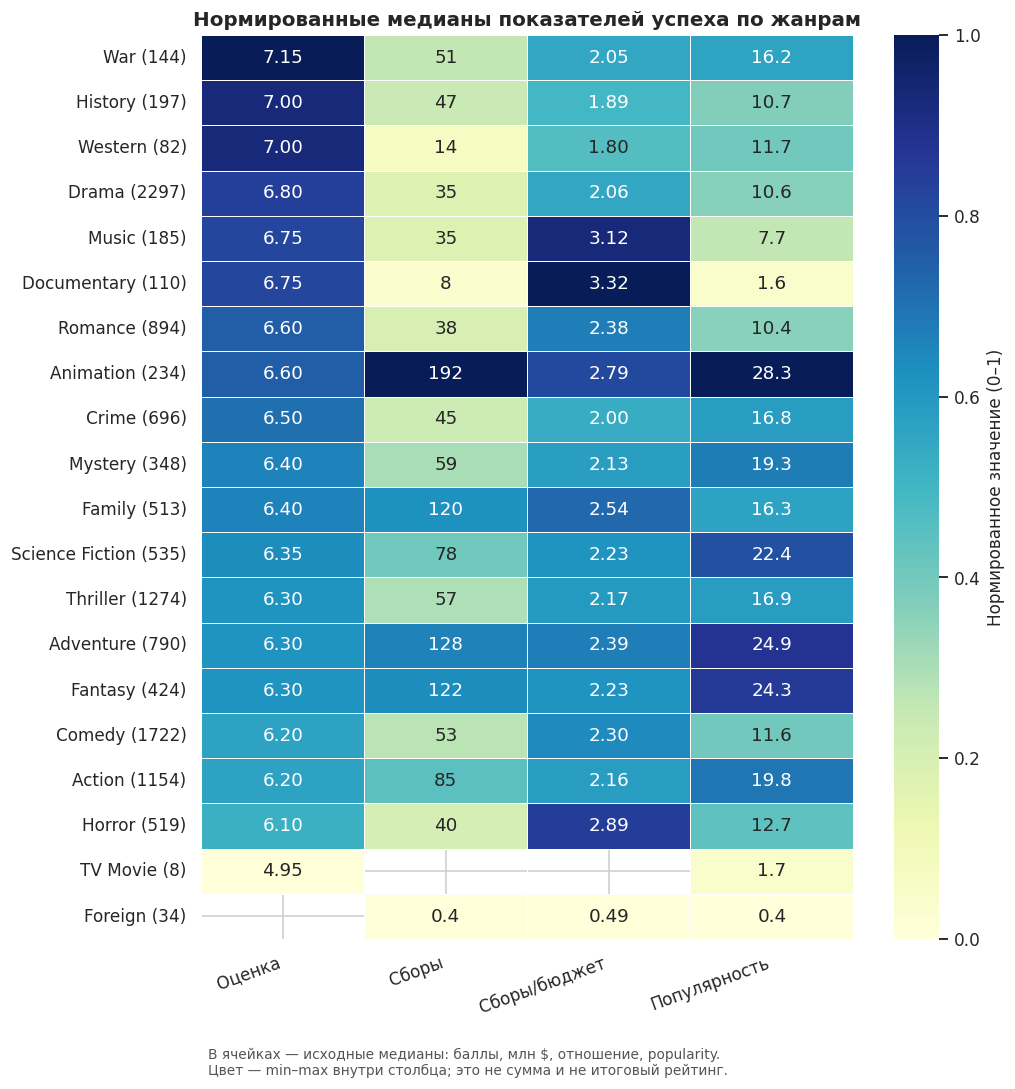

,Оценка,Сборы,Сборы/бюджет,Популярность
Оценка,1.00,-0.50,-0.34,-0.28
Сборы,-0.50,1.00,0.22,0.91
Сборы/бюджет,-0.34,0.22,1.00,0.08
Популярность,-0.28,0.91,0.08,1.00


In [18]:
heat = summary[["median_rating", "median_revenue", "median_ratio", "median_pop"]].copy()
heat.columns = ["Оценка", "Сборы", "Сборы/бюджет", "Популярность"]

norm = (heat - heat.min()) / (heat.max() - heat.min())
order = summary["median_rating"].sort_values(ascending=False).index

annot = pd.DataFrame(index=heat.index, columns=heat.columns, dtype=object)
for genre in heat.index:
    for column in heat.columns:
        value = heat.loc[genre, column]
        if pd.isna(value):
            annot.loc[genre, column] = "—"
        elif column == "Сборы":
            value_mln = value / 1e6
            annot.loc[genre, column] = f"{value_mln:.1f}" if value_mln < 1 else f"{value_mln:.0f}"
        elif column in ("Оценка", "Сборы/бюджет"):
            annot.loc[genre, column] = f"{value:.2f}"
        else:
            annot.loc[genre, column] = f"{value:.1f}"

fig, ax = plt.subplots(figsize=(9.5, 10))
sns.heatmap(
    norm.loc[order],
    mask=norm.loc[order].isna(),
    annot=annot.loc[order],
    fmt="",
    cmap="YlGnBu",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Нормированное значение (0–1)"},
    ax=ax,
)
ax.set_yticklabels([f"{genre} ({int(summary.loc[genre, 'films'])})" for genre in order], rotation=0)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Нормированные медианы показателей успеха по жанрам")
ax.text(
    0.01, -0.12,
    "В ячейках — исходные медианы: баллы, млн $, отношение, popularity.\n"
    "Цвет — min–max внутри столбца; это не сумма и не итоговый рейтинг.",
    transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#555555"
)
plt.tight_layout()
plt.show()

corr_metrics = heat.corr(method="spearman").round(2)
display(corr_metrics)

### Где показатели совпадают, а где расходятся

**Сборы и популярность** образуют одну ось: ранговая корреляция жанровых медиан — **0,91**. **Оценка** — отдельная ось: с медианными сборами она связана отрицательно (**−0,50**), с популярностью — слабо отрицательно (**−0,28**). **Отношение сборов к бюджету** почти не связано с остальными (0,22 со сборами, 0,08 с популярностью) — это действительно другая мера.

Расхождения видны на конкретных жанрах:

- **Animation** — первый по сборам (192,5 млн $) и популярности (28,33), но по оценке (6,60) уступает War, History и Drama.
- **War** — первый по оценке (7,15), но сборы 50,6 млн $ и популярность 16,18 — середина списка.
- **Drama** — самый частый жанр с высокой оценкой (6,80), но сборы 35,1 млн $ и популярность 10,56 ниже среднего.
- **Horror** — низкая оценка (6,10), но высокое отношение сборов к бюджету (2,89).
- **Music** — высокое отношение (3,12), но низкая популярность (7,72) и небольшие сборы (34,7 млн $).

Ни один жанр не лидирует по всем четырём показателям. Корреляции посчитаны по 18–20 жанровым агрегатам, а не по фильмам: это описательная связь между группами, а не доказательство влияния жанра.

## 8. Проверки устойчивости

Три проверки отвечают на конкретные вопросы:

1. Меняется ли порядок жанров при другом минимальном числе голосов?
2. Не объясняется ли порядок сборов старыми фильмами и номинальным ростом цен?
3. Насколько вывод об отношении сборов к бюджету зависит от экстремальных значений?

In [19]:
threshold_rows = []
base_medians = rating_all["median"]

for threshold in [0, 50, 100, 250, 500, 750]:
    subset = rated[rated["vote_count"] >= threshold]
    medians = subset.groupby("genre")["vote_average"].median().sort_values(ascending=False)
    common = base_medians.index.intersection(medians.index)
    threshold_rows.append({
        "Порог голосов": threshold,
        "Фильмов": subset["movie_id"].nunique(),
        "Вхождений": len(subset),
        "Лидер": medians.index[0],
        "Медиана лидера": medians.iloc[0],
        "n лидера": int((subset["genre"] == medians.index[0]).sum()),
        "Нижний жанр": medians.index[-1],
        "Медиана нижнего": medians.iloc[-1],
        "ρ с полным ranking": spearmanr(base_medians[common], medians[common]).statistic,
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

,Порог голосов,Фильмов,Вхождений,Лидер,Медиана лидера,n лидера,Нижний жанр,Медиана нижнего,ρ с полным ranking
0,0,4727,12078,Documentary,6.90,103,TV Movie,5.50,1.000
1,50,3652,9678,Documentary,7.20,36,Horror,5.85,0.982
2,100,3162,8481,Documentary,7.25,22,Horror,5.90,0.988
3,250,2344,6372,War,7.15,74,TV Movie,4.95,0.938
4,500,1612,4443,Western,7.30,21,TV Movie,6.10,0.880
5,750,1188,3307,Western,7.35,16,TV Movie,6.10,0.933


### 8.1. Порог по числу голосов

Общий порядок устойчив: ранговая корреляция с полным списком — **0,982** при 50 голосах, **0,988** при 100, **0,938** при 250, **0,880** при 500 и **0,933** при 750. Меняется только лидер: Documentary при 0–100 голосах, War при 250, Western при 500–750. Причина не в полной перестановке жанров, а в размере выборки: у лидера при порогах 500–750 остаётся 16–21 фильм, и медиана чувствительна к составу.

Практический вывод: **War, History и Drama** держатся в верхней группе, **Horror и Comedy** — в нижней, но назвать «самый высокооценённый жанр» без указания порога нельзя. Порог 250 — компромисс: сохраняет 2344 фильма и убирает основную массу оценок по нескольким голосам.

In [20]:
rev_2000 = rev[rev["year"] >= 2000].copy()

era_stats = (
    rev.groupby("genre")["revenue"]
    .agg(n="size", median="median")
    .join(
        rev_2000.groupby("genre")["revenue"].agg(n_2000="size", median_2000="median"),
        how="left",
    )
)
era_stats["median_mln"] = (era_stats["median"] / 1e6).round(1)
era_stats["median_2000_mln"] = (era_stats["median_2000"] / 1e6).round(1)
era_stats = era_stats.sort_values("median", ascending=False)

display(era_stats[["n", "median_mln", "n_2000", "median_2000_mln"]].rename(columns={
    "n": "Фильмов, все годы",
    "median_mln": "Медиана, млн $",
    "n_2000": "Фильмов, 2000+",
    "median_2000_mln": "Медиана 2000+, млн $",
}).round(1))

common = era_stats.dropna(subset=["median_2000"]).index
rho_era = spearmanr(era_stats.loc[common, "median"], era_stats.loc[common, "median_2000"]).statistic
print(f"Ранговая корреляция медиан «все годы» и «2000+»: {rho_era:.3f}")
print("Топ-5, все годы:", ", ".join(era_stats["median"].nlargest(5).index))
print("Топ-5, 2000+:", ", ".join(era_stats["median_2000"].nlargest(5).index))

,"Фильмов, все годы","Медиана, млн $","Фильмов, 2000+","Медиана 2000+, млн $"
genre,,,,
Animation,191,192.5,163,200.8
Adventure,675,127.6,463,162.8
Fantasy,351,122.5,245,156.5
Family,382,119.9,296,134.7
Action,940,85.5,654,95.0
Science Fiction,439,78.0,283,103.0
Mystery,268,58.7,181,63.8
Thriller,959,57.1,680,57.4
Comedy,1174,52.5,866,60.4


Ранговая корреляция медиан «все годы» и «2000+»: 0.979
Топ-5, все годы: Animation, Adventure, Fantasy, Family, Action
Топ-5, 2000+: Animation, Adventure, Fantasy, Family, Science Fiction


### 8.2. Сборы и период выпуска

Ограничение выборки 2000 годом почти не меняет порядок: ранговая корреляция медиан — **0,979**, топ-5 совпадает на четырёх позициях (Action уступает место Science Fiction). Медианы 2000+ выше у 18 жанров из 19 — ожидаемо из-за роста рынка и номинальных цен.

Значит, порядок сборов не является артефактом старых фильмов, но проблему инфляции это не снимает: сравнение остаётся номинальным. Кроме того, выборка — не случайная совокупность всех фильмов, а ограниченный набор записей TMDB.

In [21]:
ratio_cut = film_ratio["ratio"].quantile(0.99)
keep_ids = set(film_ratio.loc[film_ratio["ratio"] < ratio_cut, "movie_id"])
ratio_trimmed = ratio_df[ratio_df["movie_id"].isin(keep_ids)].copy()
ratio_trimmed_films = film_ratio[film_ratio["ratio"] < ratio_cut].copy()

ratio_primary = ratio_stats.copy()
ratio_robust = (
    ratio_trimmed.groupby("genre")["ratio"]
    .agg(n_trim="size", median_trim="median")
)
ratio_check = ratio_primary.join(ratio_robust).sort_values("median", ascending=False).head(8)

display(ratio_check.round(2).rename(columns={
    "n": "Фильмов",
    "median": "Медиана",
    "n_trim": "Фильмов после trim",
    "median_trim": "Медиана после trim",
}))
print(f"99-й перцентиль отношения: {ratio_cut:.1f}")
print(f"Медиана на уровне фильмов, все: {film_ratio['ratio'].median():.2f}")
print(f"Медиана на уровне фильмов после top-1%: {ratio_trimmed_films['ratio'].median():.2f}")
print(f"Исключено фильмов: {len(film_ratio) - len(ratio_trimmed_films)} из {len(film_ratio)}")
print(f"Исключено вхождений фильм–жанр: {len(ratio_df) - len(ratio_trimmed)} из {len(ratio_df)}")

,Фильмов,Медиана,Фильмов после trim,Медиана после trim
genre,,,,
Documentary,38,3.32,36,2.73
Music,111,3.12,110,3.12
Horror,332,2.89,320,2.75
Animation,188,2.79,186,2.76
Family,365,2.54,362,2.52
Adventure,661,2.39,659,2.38
Romance,574,2.38,569,2.37
Comedy,1110,2.30,1101,2.26


99-й перцентиль отношения: 71.9
Медиана на уровне фильмов, все: 2.30
Медиана на уровне фильмов после top-1%: 2.27
Исключено фильмов: 33 из 3229
Исключено вхождений фильм–жанр: 72 из 8559


### 8.3. Экстремальные отношения сборов к бюджету

После исключения 1% самых высоких отношений (порог — 71,9) медиана на уровне фильмов меняется слабо: **2,30 → 2,27**; в жанровой развёртке удалено 72 вхождения из 8559. Но лидер меняется: у Documentary медиана падает **3,32 → 2,73**, и первым становится **Music (3,12)**; у Animation (2,79 → 2,76) и Horror (2,89 → 2,75) сдвиг небольшой.

Похоже, что лидерство Documentary объясняется несколькими экстремальными малобюджетными фильмами, а не устойчивой характеристикой жанра. Для этого показателя корректнее говорить «в данных фильмы жанра чаще имеют высокое отношение», а не «жанр прибыльнее».

## 9. Ограничения и выводы

### Ограничения

1. **Выборка не случайна.** TMDB 5000 Movies — курируемая выборка фильмов, а не все фильмы мира: 93,8% записей англоязычные, малобюджетное и неанглоязычное кино представлено слабо. Выводы описывают эту выборку.
2. **Финансовые пропуски и нули не случайны.** У 29,7% фильмов нет сборов, у 21,6% — бюджета. Причины пропусков не проверялись: они могут быть связаны со старыми, независимыми и иностранными фильмами. Нули мы считаем отсутствием данных, но часть из них может быть ошибками учёта. Медианы по фильмам с известными суммами не описывают всю выборку.
3. **Сборы номинальные.** Инфляция и рост рынка не скорректированы. Проверка «2000+» показывает устойчивость порядка, но не устраняет проблему.
4. **`revenue / budget` — не прибыль.** Бюджет без маркетинга и дистрибуции, сборы валовые; в бюджетах есть ошибки, поэтому используется медиана, а не среднее.
5. **Популярность TMDB — платформенный показатель.** Она сильно связана с числом голосов и сборами, но не измеряет число зрителей, качество или культурное влияние. Значения могли измениться после выгрузки датасета.
6. **Оценки не репрезентативны для всех зрителей.** Голосуют самоотобранные пользователи TMDB; порог 250 снижает шум, но не делает выборку случайной.
7. **Жанры пересекаются, а выборки малы.** Фильм входит в каждый свой жанр, группы не независимы. У TV Movie (8 фильмов, 2 выше порога), Foreign (34, 0), Documentary (110, 10) и Western (82, 37) выборки слишком малы для уверенных выводов.
8. **Ассоциация не равна причинности.** Жанр связан со сборами, оценкой и популярностью, но не доказано, что он их вызывает: влияют бюджет, звёзды, маркетинг, время выпуска, франшизы. `credits` в анализе не использован — данные об актёрах и съёмочной группе могли бы объяснить часть различий, но выходят за рамки вопроса.

### Выводы

| Показатель успеха | Лидеры (медиана) | Слабые позиции |
|---|---|---|
| Зрительская оценка, ≥250 голосов | War 7,15; History 7,00; Western 7,00; Drama 6,80 | Horror 6,10; Comedy 6,20 |
| Сборы | Animation 192,5 млн $; Adventure 127,6; Fantasy 122,5 | Foreign 0,4; Documentary 7,9; Western 14,5 |
| Сборы / бюджет* | Music 3,12; Horror 2,89; Animation 2,79 | Foreign 0,49; Western 1,80; History 1,89 |
| Популярность | Animation 28,3; Adventure 24,9; Fantasy 24,3 | Foreign 0,4; Documentary 1,6; TV Movie 1,7 |

\* Для отношения сборов к бюджету указаны значения после исключения 1% экстремальных наблюдений.

**Главный ответ.** Единого «самого успешного жанра» в этих данных нет. Animation выигрывает по сборам и популярности, War — по оценке, Music — по отдаче на доллар бюджета; Drama сочетает высокую оценку с огромной распространённостью, но не лидирует по сборам. Ответ зависит от того, какое измерение успеха выбрано и на какой выборке оно посчитано.

**Что устойчиво.** Высокие позиции War, History и Drama по оценке и низкие — Horror и Comedy; лидерство Animation, Adventure, Fantasy и Family по сборам (ρ=1,000 после удаления топ-1% и 0,979 при срезе 2000+); связь сборов и популярности (0,91) и независимость отношения сборов к бюджету.

**Что неустойчиво.** Конкретный лидер по оценке (Documentary → War → Western при разных порогах) и по отношению сборов к бюджету (Documentary → Music после удаления экстремальных значений). Распространённость жанра тоже не равна успеху: Drama и Comedy — самые частые, но не лидируют по сборам.

Причинно-следственных выводов данные не позволяют: жанр лишь связан с показателями, а различия могут объясняться бюджетом, маркетингом, временем выпуска и составом выборки.